# 06 — Optuna, validasi silang, dan prediksi OOF

**File:** `06_Optuna_CV_dan_OOF.ipynb`

Kita melihat apa yang dioptimalkan, bagaimana validasi dilakukan, dan dari mana ambang tambahan berasal. Kita membaca empat studi yang sudah selesai dan menghitung ulang ambang dari OOF tersimpan. Tidak ada trial atau fitting baru.

**Input:** protokol, trials.csv, ringkasan tuning/CV, prediksi OOF dan ambang tersimpan. **Hubungan tahap:** 05: classifier/bobot train → notebook ini → 07: seleksi dan evaluasi test.

**Cara menjalankan:** pilih kernel `.venv` project, lalu **Restart Kernel and Run All**. Setiap notebook memuat datanya sendiri; tidak memerlukan variabel notebook lain. Source yang tampil dibaca langsung dari fungsi dalam `KODE_ML/03_Kode/` yang di-import, bukan salinan contoh.

**Batas eksekusi:** Run All bawaan membaca hasil utama yang tersimpan dan menjalankan pemeriksaan ringan. Menampilkan definisi fungsi tidak menjalankan training di dalamnya. Hasil lama dan hasil eksekusi pemeriksaan dibedakan pada tiap blok. Training baru hanya melalui gerbang eksplisit di notebook 07, yang default-nya mati.

## Persiapan: pastikan sumber berasal dari KODE_ML

Blok ini mencari folder sumber, menambahkannya ke jalur import, dan memeriksa alamat modul. `sys.dont_write_bytecode` mencegah penulisan cache Python saat belajar. Output alamat membantu mendeteksi bila kita tidak sengaja membuka salinan project lain.

In [1]:
from pathlib import Path
import sys

lokasi = Path.cwd().resolve()
kandidat = [p for induk in [lokasi, *lokasi.parents]
            for p in (induk, induk / "KODE_ML")]
kandidat.append(Path(r"C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML"))
KODE_ML = next((p for p in kandidat if (p / "03_Kode/runtime.py").is_file()), None)
if KODE_ML is None:
    raise FileNotFoundError("Buka notebook dari folder KODE_ML yang lengkap.")
sys.dont_write_bytecode = True
sys.path.insert(0, str(KODE_ML.parent))
sys.path.insert(0, str(KODE_ML))
from IPython.display import display, Markdown
from belajar import tampilkan_sumber, tampilkan_awal
from research import runtime
assert Path(runtime.__file__).resolve().is_relative_to(KODE_ML.resolve())
print("Source aktif:", Path(runtime.__file__).resolve().parent)

Source aktif: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML\03_Kode


### Baca kebijakan tuning

Empat studi adalah XGBoost C/D dan LightGBM C/D. Masing-masing mendapat 8 jam komputasi aktif; total 32 jam tuning, di luar repeated CV/final fit. Budget sama tidak menjamin jumlah trial sama.

In [2]:
import numpy as np
import pandas as pd
import optuna
from research import tuning, validation, experiment
from research.results import main_run

protocol = runtime.read(experiment.PROTOCOL)
run = main_run()
display(pd.DataFrame([protocol["tuning"]]).T.rename(columns={0: "nilai"}))
display(pd.DataFrame([
    {"kelompok": group, "parameter": name, **spec}
    for group in ("common", "xgb", "lgbm")
    for name, spec in protocol["search_space"][group].items()
]))

,nilai
seconds_per_study,28800
seconds_total,115200
heartbeat_seconds,15
safety_max_trials,10000
sampler,TPESampler
seed,42
n_startup_trials,10
n_ei_candidates,24
multivariate,False
study_policy,"Four fresh studies C/D, 8 hours each. Same gen..."


,kelompok,parameter,kind,low,high,step,log
0,common,n_estimators,int,100.000000,1600.0,100.0,NaN
1,common,learning_rate,float,0.005000,0.2,NaN,True
2,common,max_depth,int,3.000000,8.0,NaN,NaN
3,common,colsample_bytree,float,0.300000,1.0,NaN,NaN
4,common,subsample,float,0.600000,1.0,NaN,NaN
5,common,reg_alpha,float,0.000001,10.0,NaN,True
6,common,reg_lambda,float,0.001000,100.0,NaN,True
7,xgb,min_child_weight,float,1.000000,30.0,NaN,True
8,xgb,gamma,float,0.000000,5.0,NaN,NaN
9,lgbm,min_child_samples,int,10.000000,150.0,NaN,NaN


### Import dan konstanta `tuning.py`

`optuna` mengatur studi/sampler, `time` mengukur budget, dan `joblib` menyimpan keadaan sampler. Objective memanggil fungsi CV yang dijelaskan setelah bagian tuning.

In [3]:
tampilkan_awal(tuning)

**Import dan konstanta aktual:** `KODE_ML/03_Kode/tuning.py`. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
"""Fresh TPE studies with equal wall-clock budgets and atomic sampler checkpoints."""
from datetime import datetime, timezone
from pathlib import Path
import time
import joblib
import optuna
from . import runtime as core
from .validation import cross_validate
from .metrics import summarize

```

### `tuning.suggest` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** trial, algoritma, protokol. **Output:** parameter satu trial.

`kind` menentukan integer/float; range, log, dan step dibaca dari konfigurasi. Parameter umum digabung dengan parameter algoritma. LightGBM membatasi `num_leaves` mengikuti `max_depth` lalu menambahkan `subsample_freq=1`. Usulan parameter belum berarti bagus sebelum dinilai lewat CV.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [4]:
tampilkan_sumber(tuning.suggest)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 25–36. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
def suggest(trial, algorithm, protocol):
    space = protocol['search_space']
    params = {}
    for name, spec in {**space['common'], **space[algorithm]}.items():
        kwargs = {k:v for k,v in spec.items() if k!='kind'}
        params[name] = (trial.suggest_int if spec['kind']=='int' else trial.suggest_float)(name, **kwargs)
    if algorithm == 'lgbm':
        leaves = space['lgbm_num_leaves']
        high = min(leaves['high'], 2**params['max_depth']) if leaves['cap_by_depth'] else leaves['high']
        params['num_leaves'] = trial.suggest_int('num_leaves', leaves['low'], high)
        params.update(space['lgbm_fixed'])
    return params

```

### Cek recipe awal tanpa studi baru

`FixedTrial` hanya mengembalikan recipe yang telah ditentukan. Tidak membuat database, trial pencarian baru, atau training.

In [5]:
for algorithm in experiment.ALGORITHMS:
    recipe = protocol["initial_recipes"][algorithm]
    assert tuning.suggest(optuna.trial.FixedTrial(recipe), algorithm, protocol) == recipe
print("Recipe awal cocok dengan ruang pencarian.")

Recipe awal cocok dengan ruang pencarian.


### `tuning.atomic_dump` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** objek dan alamat file. **Output:** checkpoint saat fungsi dipanggil oleh training. File sementara ditulis lebih dulu lalu mengganti tujuan, untuk mengurangi risiko checkpoint setengah tertulis. Ini ketahanan proses, bukan modifikasi algoritma.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [6]:
tampilkan_sumber(tuning.atomic_dump)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 11–15. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
def atomic_dump(value, path):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    joblib.dump(value, temp)
    temp.replace(path)

```

### `tuning.event` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** folder run, tahap, detail kemajuan. **Output:** progress.json, events.jsonl, pesan terminal. Catatan membuat trial dan waktu dapat ditelusuri; fungsi tidak dipanggil pada sesi baca hasil ini.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [7]:
tampilkan_sumber(tuning.event)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 17–23. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
def event(run, stage, **details):
    value = {'time': datetime.now(timezone.utc).isoformat(), 'stage':stage, **details}
    core.write(Path(run)/'progress.json', value)
    with (Path(run)/'events.jsonl').open('a',encoding='utf-8') as f:
        import json
        f.write(json.dumps(value)+'\n')
    print(f"[{value['time']}] {stage}: {details}", flush=True)

```

### `tuning.initialize` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** run, kandidat, protokol, recipe awal. **Output:** studi Optuna terhubung SQLite.

Sampler TPE memakai seed/parameter terkunci; arah studi `maximize`. Recipe awal diantrekan sebagai trial pertama. Saat resume, budget dan checkpoint sampler wajib cocok. Skor trial historis tidak diimpor sebagai trial selesai.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [8]:
tampilkan_sumber(tuning.initialize)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 38–59. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
def initialize(run, key, protocol, recipe):
    folder = Path(run)/key
    folder.mkdir(parents=True,exist_ok=True)
    state_path = folder/'budget.json'
    policy = protocol['tuning']
    sampler_path = folder/'sampler.joblib'
    sampler = optuna.samplers.TPESampler(seed=policy['seed'],n_startup_trials=policy['n_startup_trials'],n_ei_candidates=policy['n_ei_candidates'],multivariate=policy['multivariate'])
    study = optuna.create_study(study_name=key,storage=f"sqlite:///{(folder/'optuna.sqlite3').as_posix()}",direction='maximize',sampler=sampler,load_if_exists=True)
    if state_path.exists():
        state = core.read(state_path)
        if state['budget_seconds'] != policy['seconds_per_study']:
            raise ValueError('Cannot change budget while resuming.')
        if not sampler_path.exists(): raise ValueError('Missing sampler checkpoint.')
    else:
        if any(t.state != optuna.trial.TrialState.WAITING for t in study.trials):
            raise ValueError('Study exists without budget evidence; do not import historical trials.')
        queued = {k:v for k,v in recipe.items() if k!='subsample_freq'}
        study.enqueue_trial(queued,skip_if_exists=True)
        atomic_dump(sampler,sampler_path)
        core.write(state_path,{'budget_seconds':policy['seconds_per_study'],'charged_seconds':0.,'status':'initialized','active_trial':None,'source_completed_trials':0})
    study.sampler=joblib.load(sampler_path)
    return study

```

### `tuning.BudgetLimits` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** tenggat, callback pencatat, interval. **Output:** objek pemeriksa batas.

`check()` mencatat waktu berkala lalu memanggil batas induknya. Ini bukan pruning berbasis skor; trial bisa dihentikan saat budget habis.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [9]:
tampilkan_sumber(tuning.BudgetLimits)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 61–70. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
class BudgetLimits(core.Limits):
    def __init__(self, deadline, callback, interval):
        super().__init__(deadline)
        self.callback, self.interval, self.last = callback, interval, 0.
    def check(self, force=False):
        now=time.perf_counter()
        if now-self.last>=self.interval:
            self.callback(now)
            self.last=now
        super().check(force)

```

### `tuning.tune` — kode aktual

**File:** `KODE_ML/03_Kode/tuning.py`.

**Input:** kandidat, fitur/target train, metadata/fold, protokol, recipe awal. **Output:** parameter trial selesai dengan AP CV tertinggi.

1. Buka studi; tandai trial terputus sebagai gagal.
2. Hitung sisa budget; resume tidak mendapat 8 jam baru.
3. `ask()` → `suggest()` → `cross_validate()` → rata-rata AP → `tell()`.
4. Waktu trial gagal tetap dibebankan; sampler/CSV/budget disimpan.
5. Pilih trial selesai terbaik; tie memakai nomor trial lebih awal.

Objective adalah rata-rata AP antar-fold per label lalu antar-label. **AP trial terbaik, mean AP lima seed, dan AP test adalah tiga angka berbeda.**

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [10]:
tampilkan_sumber(tuning.tune)

**Source aktual:** `KODE_ML/03_Kode/tuning.py`, baris 72–134. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `af497eb63c357a7f08bd7f1e3a3a73966ca925bf267b96d2de09bb1122b92531`.

```python
def tune(run, key, algorithm, x, y, meta, split, positions, protocol, initial_recipe):
    folder=Path(run)/key
    study=initialize(run,key,protocol,initial_recipe)
    for t in study.trials:
        if t.state == optuna.trial.TrialState.RUNNING:
            study.tell(t.number,state=optuna.trial.TrialState.FAIL)
    state_path=folder/'budget.json'
    state=core.read(state_path)
    policy=protocol['tuning']
    remaining=max(0.,policy['seconds_per_study']-state['charged_seconds'])
    if remaining>1 and len(study.trials)<policy['safety_max_trials']:
        started=time.perf_counter(); charged=state['charged_seconds']; last_log=started
        def heartbeat(now):
            nonlocal last_log
            state.update(charged_seconds=min(policy['seconds_per_study'],charged+now-started),last_heartbeat_at=datetime.now(timezone.utc).isoformat(),status='running')
            core.write(state_path,state)
            if now-last_log>=60:
                event(run,'tuning',candidate=key,trial=state['active_trial'],hours_used=round(state['charged_seconds']/3600,3),hours_budget=policy['seconds_per_study']/3600)
                last_log=now
        limits=BudgetLimits(started+remaining,heartbeat,policy['heartbeat_seconds'])
        try:
            while time.perf_counter()<limits.deadline and len(study.trials)<policy['safety_max_trials']:
                trial=study.ask()
                state['active_trial']=trial.number
                heartbeat(time.perf_counter())
                try:
                    params=suggest(trial,algorithm,protocol)
                    trial.set_user_attr('resolved_parameters',params)
                    atomic_dump(study.sampler,folder/'sampler.joblib')
                    event(run,'trial_started',candidate=key,trial=trial.number)
                    values=cross_validate(algorithm,params,x,y,meta['labels'],split['folds'],positions,limits,meta['summary_labels'])
                    score=summarize(values,meta['summary_labels'])['metrics']['auprc']
                    study.tell(trial,score)
                    event(run,'trial_completed',candidate=key,trial=trial.number,macro_ap=score,best_macro_ap=study.best_value)
                except TimeoutError:
                    trial.set_user_attr('stop_reason','budget_exhausted')
                    study.tell(trial,state=optuna.trial.TrialState.FAIL)
                    break
                except BaseException:
                    trial.set_user_attr('stop_reason','interrupted_or_error')
                    study.tell(trial,state=optuna.trial.TrialState.FAIL)
                    raise
                finally:
                    state['active_trial']=None
                    atomic_dump(study.sampler,folder/'sampler.joblib')
                    study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
                    heartbeat(time.perf_counter())
        finally:
            state.update(charged_seconds=min(policy['seconds_per_study'],charged+time.perf_counter()-started),active_trial=None)
            state['status']='complete' if state['charged_seconds']>=policy['seconds_per_study']-1 else 'paused'
            state['stop_reason']='time_budget_exhausted' if state['status']=='complete' else 'interrupted_or_safety_limit'
            core.write(state_path,state)
            atomic_dump(study.sampler,folder/'sampler.joblib')
            study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
    else:
        study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
    done=[t for t in study.trials if t.state==optuna.trial.TrialState.COMPLETE]
    if not done: raise RuntimeError(f'{key}: no completed trial; preserve run for investigation.')
    if state['charged_seconds']<policy['seconds_per_study']-1:
        raise RuntimeError('Safety trial cap reached before full budget; do not treat as complete.')
    best=max(done,key=lambda t:(t.value,-t.number))
    core.write(folder/'tuning_summary.json',{'complete_trials':len(done),'failed_trials':sum(t.state==optuna.trial.TrialState.FAIL for t in study.trials),'best_trial':best.number,'best_macro_ap':best.value,'completed_trials_after_best':sum(t.number>best.number for t in done),'budget':state,'initial_recipe_recomputed':True})
    return best.user_attrs['resolved_parameters']

```

### Baca hasil empat studi sebenarnya

Jumlah trial selesai dan AP terbaik di CSV diperiksa terhadap JSON. File yang dibaca berasal dari hasil utama; tidak ada pemanggilan initialize/tune.

In [11]:
rows, completed_by_key = [], {}
for key in experiment.TUNED:
    summary = runtime.read(run / key / "tuning_summary.json")
    trials = pd.read_csv(run / key / "trials.csv")
    completed = trials.loc[trials.state.eq("COMPLETE")].sort_values("number")
    assert len(completed) == summary["complete_trials"]
    assert np.isclose(completed.value.max(), summary["best_macro_ap"])
    completed_by_key[key] = completed
    rows.append({"kandidat": key, "selesai": summary["complete_trials"],
                 "gagal": summary["failed_trials"], "trial_terbaik": summary["best_trial"],
                 "AP_trial_terbaik": summary["best_macro_ap"],
                 "jam_terpakai": summary["budget"]["charged_seconds"] / 3600})
display(pd.DataFrame(rows))
display(completed_by_key["lgbm_D"][["number", "value", "duration"]])

,kandidat,selesai,gagal,trial_terbaik,AP_trial_terbaik,jam_terpakai
0,xgb_C,12,1,2,0.267352,8.0
1,xgb_D,12,1,2,0.298033,8.0
2,lgbm_C,104,1,56,0.270096,8.0
3,lgbm_D,74,1,73,0.301979,8.0


,number,value,duration
0,0,0.290847,0 days 00:01:46.454275
1,1,0.221665,0 days 00:02:30.533232
2,2,0.292991,0 days 00:06:26.485500
3,3,0.280660,0 days 00:03:39.580697
4,4,0.264883,0 days 00:02:12.002975
...,...,...,...
69,69,0.300095,0 days 00:10:06.986349
70,70,0.294938,0 days 00:07:44.565702
71,71,0.301094,0 days 00:07:55.988274
72,72,0.301580,0 days 00:07:28.158300


### Visualisasi perkembangan trial

Garis adalah AP terbaik sampai nomor trial tersebut, dari trial selesai saja. Nomor trial tetap nomor asli. Garis mendatar berarti belum ada perbaikan pada trial yang terlihat, bukan bukti optimum global.

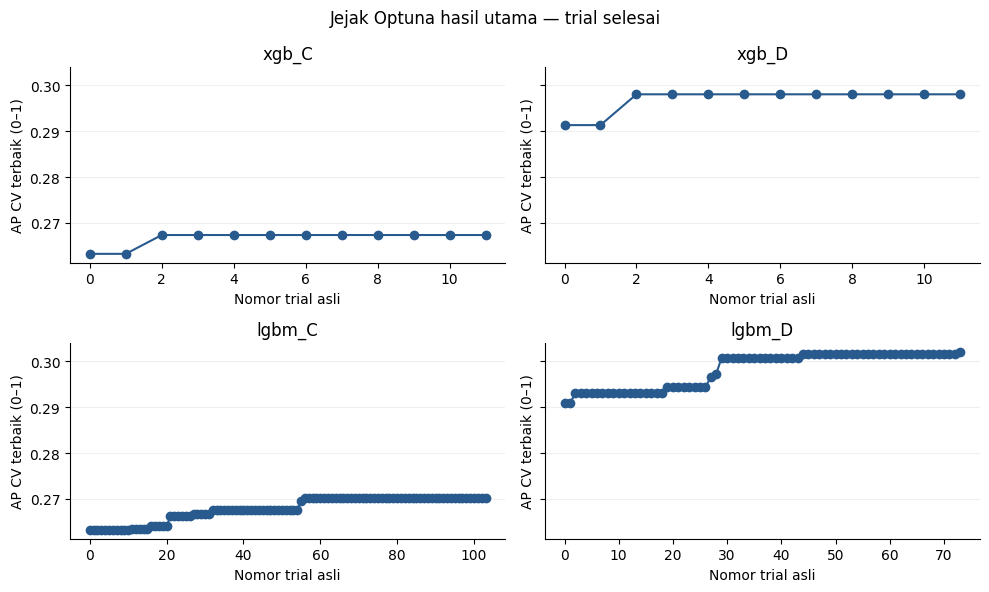

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, key in zip(axes.flat, experiment.TUNED):
    values = completed_by_key[key]
    ax.plot(values.number, values.value.cummax(), marker="o", color="#285A8E")
    ax.set(title=key, xlabel="Nomor trial asli", ylabel="AP CV terbaik (0–1)")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Jejak Optuna hasil utama — trial selesai")
fig.tight_layout()
plt.show()

### Import dan konstanta `validation.py`

Modul ini memakai fit dari training, pembentuk fold kelompok, dan metrik yang sama. Output OOF disimpan bersama target/urutan label supaya indeks bisa diperiksa.

In [13]:
tampilkan_awal(validation)

**Import dan konstanta aktual:** `KODE_ML/03_Kode/validation.py`. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
"""CV per label, prediksi OOF, dan ambang tambahan dari train saja."""
import numpy as np
from .runtime import read, write, save_npz, Limits, WEIGHTING_POLICY
from .training import fit
from .splits import POLICY, inner_folds
from .metrics import METRICS, binary_metrics, summarize

```

### `validation.cross_validate` — kode aktual

**File:** `KODE_ML/03_Kode/validation.py`.

**Input:** recipe, fitur/target train, fold per label, pemetaan posisi, batas waktu. **Output:** metrik rata-rata fold per label; opsional checkpoint dan OOF.

`positions` memetakan indeks dataset ke array train. Tiap label/fold melatih pada `tr` dan memprediksi `va`; skor ditaruh kembali ke posisi validation asalnya. Setelah semua fold, tiap baris mempunyai prediksi dari model yang tidak melatih baris tersebut pada pengulangan itu. Keputusan memakai 0,5; AP memakai skor kontinu.

Fold dibentuk **per label**. Antar-kandidat, fold untuk label+seed yang sama harus identik; tidak berarti semua label pasti mempunyai daftar fold identik.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [14]:
tampilkan_sumber(validation.cross_validate)

**Source aktual:** `KODE_ML/03_Kode/validation.py`, baris 8–66. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
def cross_validate(algorithm, params, x, y, labels, folds, positions, limits, wanted,
                   checkpoint=None, detail_path=None, oof_path=None):
    """Evaluate per label; optional artifacts make the final CV fully auditable."""
    result = read(checkpoint) if checkpoint and checkpoint.exists() else {}
    details = read(detail_path) if detail_path and detail_path.exists() else {}
    oof_probabilities = np.full(y.shape, np.nan, dtype=np.float32)
    oof_decisions = np.full(y.shape, -1, dtype=np.int8)
    if oof_path and oof_path.exists():
        with np.load(oof_path, allow_pickle=False) as saved:
            oof_probabilities = saved["probabilities"]
            oof_decisions = saved["decisions"]
        if oof_probabilities.shape != y.shape or oof_decisions.shape != y.shape:
            raise ValueError("OOF checkpoint shape changed.")

    for name in wanted:
        j = labels.index(name)
        artifacts_ready = (
            (detail_path is None or name in details)
            and (oof_path is None or np.isfinite(oof_probabilities[:, j]).all())
        )
        if name in result and artifacts_ready:
            continue
        fold_values = []
        fold_details = []
        oof_probabilities[:, j] = np.nan
        oof_decisions[:, j] = -1
        for fold_index, fold in enumerate(folds[name]):
            tr = np.array([positions[i] for i in fold["train"]], dtype=int)
            va = np.array([positions[i] for i in fold["validation"]], dtype=int)
            model = fit(algorithm, params, x[tr], y[tr, j], limits)
            probabilities = model.predict_proba(x[va])[:, 1]
            decisions = (probabilities >= 0.5).astype(np.int8)
            metrics = binary_metrics(y[va, j], probabilities, decisions)
            fold_values.append(metrics)
            fold_details.append({
                "fold": fold_index,
                "training_rows": int(len(tr)),
                "validation_rows": int(len(va)),
                "training_positives": int(y[tr, j].sum()),
                "validation_positives": int(y[va, j].sum()),
                "metrics": metrics,
            })
            oof_probabilities[va, j] = probabilities
            oof_decisions[va, j] = decisions
        if not np.isfinite(oof_probabilities[:, j]).all() and oof_path:
            raise ValueError(f"OOF coverage incomplete for label {name}.")
        result[name] = {
            metric: float(np.mean([value[metric] for value in fold_values]))
            for metric in METRICS
        }
        details[name] = fold_details
        if checkpoint:
            write(checkpoint, result)
        if detail_path:
            write(detail_path, details)
        if oof_path:
            save_npz(oof_path, probabilities=oof_probabilities, decisions=oof_decisions,
                     truth=y, labels=np.asarray(labels))
    return result

```

### `validation.f1_from_metrics` — kode aktual

**File:** `KODE_ML/03_Kode/validation.py`.

**Input:** precision/recall satu label. **Output:** `2PR/(P+R)`, atau 0 bila penyebut 0. Macro-F1 merata-ratakan F1 per label, bukan menghitung F1 dari precision-macro dan recall-macro.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [15]:
tampilkan_sumber(validation.f1_from_metrics)

**Source aktual:** `KODE_ML/03_Kode/validation.py`, baris 69–71. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
def f1_from_metrics(value):
    precision, recall = value["precision"], value["recall"]
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

```

### `validation.prediction_diagnostics` — kode aktual

**File:** `KODE_ML/03_Kode/validation.py`.

**Input:** target, keputusan biner, label. **Output:** rata-rata banyak label sebenarnya/prediksi, proporsi positif, macro-F1, jumlah label. Diagnostik melihat apakah model terlalu jarang/banyak memberi label. AP/AUROC utama tetap dihitung dengan probabilitas asli di jalur metrik.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [16]:
tampilkan_sumber(validation.prediction_diagnostics)

**Source aktual:** `KODE_ML/03_Kode/validation.py`, baris 74–86. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
def prediction_diagnostics(truth, decisions, labels):
    per_label = [
        binary_metrics(truth[:, j], decisions[:, j].astype(float), decisions[:, j])
        for j in range(len(labels))
    ]
    return {
        "mean_true_labels_per_molecule": float(np.mean(np.sum(truth, axis=1))),
        "mean_predicted_labels_per_molecule": float(np.mean(np.sum(decisions, axis=1))),
        "true_positive_rate": float(np.mean(truth)),
        "predicted_positive_rate": float(np.mean(decisions)),
        "macro_f1": float(np.mean([f1_from_metrics(value) for value in per_label])),
        "label_count": len(labels),
    }

```

### `validation.select_validation_thresholds` — kode aktual

**File:** `KODE_ML/03_Kode/validation.py`.

**Input:** target train, skor OOF, label, grid ambang. **Output:** ambang tambahan per label.

Fungsi mencoba grid dan memilih F1 OOF tertinggi. Tie dipecahkan melalui kedekatan ke 0,5 lalu nilai ambang. Test tidak dipakai memilih ambang. F1 OOF setelah pemilihan ambang tetap bukti pengembangan, bukan evaluasi independen. **Ambang utama tetap 0,5.**

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [17]:
tampilkan_sumber(validation.select_validation_thresholds)

**Source aktual:** `KODE_ML/03_Kode/validation.py`, baris 89–116. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
def select_validation_thresholds(truth, probabilities, labels, grid):
    """Choose each label threshold from OOF validation predictions only."""
    thresholds = {}
    fixed_grid = sorted({float(value) for value in grid} | {0.5})
    for j, name in enumerate(labels):
        candidates = []
        for threshold in fixed_grid:
            decisions = (probabilities[:, j] >= threshold).astype(np.int8)
            value = binary_metrics(truth[:, j], probabilities[:, j], decisions)
            candidates.append((f1_from_metrics(value), -abs(threshold - 0.5), threshold, value))
        best_f1, _, threshold, metrics = max(candidates, key=lambda item: item[:3])
        at_half = binary_metrics(
            truth[:, j], probabilities[:, j], (probabilities[:, j] >= 0.5).astype(np.int8)
        )
        thresholds[name] = {
            "threshold": threshold,
            "oof_f1": best_f1,
            "oof_f1_at_0_5": f1_from_metrics(at_half),
            "oof_precision": metrics["precision"],
            "oof_recall": metrics["recall"],
            "training_positives": int(truth[:, j].sum()),
        }
    return {
        "method": "per-label maximum F1 on repeated grouped OOF probabilities",
        "selection_data": "training-validation only; held-out test is never used",
        "grid": fixed_grid,
        "labels": thresholds,
    }

```

### `validation.repeated_grouped_cv` — kode aktual

**File:** `KODE_ML/03_Kode/validation.py`.

**Input:** satu kandidat/recipe, data train, grup, label, protokol. **Output:** lima hasil CV, rata-rata skor OOF, ambang tambahan, mean/SD metrik.

Urutannya seed 7 → seluruh fold, seed 21 → seluruh fold, lalu 42, 84, 100. Angka seed bukan jumlah putaran. `np.stack` mengumpulkan skor yang sejajar per baris/label; `mean(axis=0)` merata-ratakan skor OOF lima pengulangan.

Mean AP per seed berbeda dengan AP dari skor OOF rata-rata. Ini repeated CV, bukan nested CV; lima seed memakai data yang sama dan tidak independen.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [18]:
tampilkan_sumber(validation.repeated_grouped_cv)

**Source aktual:** `KODE_ML/03_Kode/validation.py`, baris 119–180. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `7c0f86601d8c619b7a2c1d76e86659ab41bd0533f0cdac2a5f99700624877c6c`.

```python
def repeated_grouped_cv(run, key, algorithm, params, x, y, labels, groups, protocol):
    """Evaluate one candidate across the fixed grouped-CV repetitions."""
    folder = run / "robustness" / key
    folder.mkdir(parents=True, exist_ok=True)
    seeds = protocol["robustness"]["seeds"]
    max_folds = protocol["robustness"]["folds"]
    local_indices = np.arange(len(y), dtype=int)
    positions = {int(i): int(i) for i in local_indices}
    summaries, probability_runs = {}, []
    for seed in seeds:
        seed_folder = folder / f"seed_{seed}"
        seed_folder.mkdir(exist_ok=True)
        generated = {
            name: inner_folds(local_indices, y[:, j], groups, max_folds, seed)
            for j, name in enumerate(labels)
        }
        write(seed_folder / "folds.json", {
            "seed": seed,
            "group_policy": POLICY,
            "folds": generated,
        })
        values = cross_validate(
            algorithm, params, x, y, labels, generated, positions, Limits(), labels,
            seed_folder / "cv_per_label.json",
            seed_folder / "cv_fold_metrics.json",
            seed_folder / "cv_oof_predictions.npz",
        )
        summary = summarize(values, labels)
        summaries[str(seed)] = summary
        write(seed_folder / "cv_summary.json", summary)
        with np.load(seed_folder / "cv_oof_predictions.npz", allow_pickle=False) as saved:
            probability_runs.append(saved["probabilities"])

    pooled = np.mean(np.stack(probability_runs), axis=0)
    decisions = (pooled >= 0.5).astype(np.int8)
    save_npz(folder / "pooled_oof_predictions.npz", probabilities=pooled,
             decisions=decisions, truth=y, labels=np.asarray(labels),
             seeds=np.asarray(seeds, dtype=int))
    thresholds = select_validation_thresholds(
        y, pooled, labels, protocol["threshold_selection"]["grid"]
    )
    write(folder / "thresholds.json", thresholds)
    mean_metrics = {
        metric: float(np.mean([summary["metrics"][metric] for summary in summaries.values()]))
        for metric in METRICS
    }
    std_metrics = {
        metric: float(np.std([summary["metrics"][metric] for summary in summaries.values()], ddof=1))
        for metric in METRICS
    }
    result = {
        "candidate": key,
        "seeds": seeds,
        "folds_per_label_maximum": max_folds,
        "mean_metrics": mean_metrics,
        "std_metrics": std_metrics,
        "per_seed": summaries,
        "oof_diagnostics_at_0_5": prediction_diagnostics(y, decisions, labels),
        "weighting_policy": WEIGHTING_POLICY,
    }
    write(folder / "robustness_summary.json", result)
    return result

```

### Hitung ulang ambang dari OOF tersimpan

Kandidat diambil dari pilihan beku. Target OOF adalah outer train, bukan 20% test. Seluruh dictionary ambang hasil ulang dibandingkan dengan artefak; ini tidak memerlukan fit.

In [19]:
selected = runtime.read(run / "selection_frozen.json")["overall_selected_from_repeated_grouped_cv"]
folder = run / "robustness" / selected
cv = runtime.read(folder / "robustness_summary.json")
display(pd.DataFrame([{"seed": seed, **value["metrics"]} for seed, value in cv["per_seed"].items()]))
with np.load(folder / "pooled_oof_predictions.npz", allow_pickle=False) as data:
    truth, probabilities, labels = data["truth"], data["probabilities"], data["labels"].tolist()
    print({"truth_OOF": truth.shape, "skor_OOF": probabilities.shape, "seed": data["seeds"].tolist()})
recomputed = validation.select_validation_thresholds(truth, probabilities, labels, protocol["threshold_selection"]["grid"])
assert recomputed == runtime.read(folder / "thresholds.json")
display(pd.DataFrame.from_dict(recomputed["labels"], orient="index").head(12))
print("Seluruh ambang identik dengan hasil tersimpan.")

,seed,accuracy,auroc,auprc,specificity,precision,recall
0,7,0.929324,0.838574,0.299420,0.939613,0.223914,0.475616
1,21,0.929124,0.836666,0.298343,0.939416,0.224666,0.478555
2,42,0.929174,0.840113,0.301979,0.939335,0.224233,0.479372
3,84,0.929039,0.835199,0.299749,0.939389,0.223184,0.474344
4,100,0.929126,0.837257,0.299164,0.939558,0.223717,0.476607


{'truth_OOF': (5353, 109), 'skor_OOF': (5353, 109), 'seed': [7, 21, 42, 84, 100]}


,threshold,oof_f1,oof_f1_at_0_5,oof_precision,oof_recall,training_positives
acidic,0.90,0.333333,0.256881,0.500000,0.250000,36
aldehydic,0.65,0.349754,0.325411,0.279528,0.467105,152
almond,0.70,0.345238,0.251656,0.353659,0.337209,86
amber,0.65,0.347368,0.292490,0.284483,0.445946,74
animal like,0.65,0.369048,0.326360,0.344444,0.397436,156
anisic,0.60,0.436548,0.378151,0.377193,0.518072,83
apple,0.80,0.468531,0.410768,0.507576,0.435065,308
apricot,0.50,0.254237,0.254237,0.178571,0.441176,102
aromatic,0.75,0.119658,0.110638,0.179487,0.089744,78
balsamic,0.65,0.464286,0.398210,0.415414,0.526190,420


Seluruh ambang identik dengan hasil tersimpan.


## Bekal sidang

- **Optuna langsung tahu yang terbaik?** Tidak; TPE mengusulkan parameter berdasarkan trial sebelumnya, lalu setiap usulan tetap diuji.
- **OOF itu data test?** Bukan; OOF berasal dari validation dalam outer train.
- **Lima seed menghapus semua bias?** Tidak; itu pemeriksaan kestabilan pembagian, bukan jaminan generalisasi atau lima eksperimen independen.
- **Apa yang dihitung ulang?** Pemeriksaan recipe, ringkasan trial, dan ambang dari skor OOF. Tidak ada classifier di-fit.

Lanjut: **07_Evaluasi_dan_Pemilihan.ipynb**.